Make sure that `Riyadh Marathon Results.csv` is uploaded

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df=pd.read_csv('/content/Riyadh Marathon Results.csv')

#Task 1 — Missing Values

* Count missing values

* Calculate percentage

* Which column has highest missing rate?

* Decide action

In [ ]:
df.isnull().sum()

,0
Unnamed: 0,0
Rank,0
Gender Rank,0
Name,0
Gender,0
Category,0
Nationality,312
Gun Time,0
Chip Time,170
Speed,170


In [ ]:
(df.isnull().sum())/len(df)*100

,0
Unnamed: 0,0.000000
Rank,0.000000
Gender Rank,0.000000
Name,0.000000
Gender,0.000000
Category,0.000000
Nationality,4.877286
Gun Time,0.000000
Chip Time,2.657496
Speed,2.657496


In [ ]:
# column 'Nationality' has the highest missing rate, followed by chip time, speed, and pace

In [ ]:
# seeing that 'Nationality' isn't a priority for now, we'll deal with it later

#Task 2 — Duplicate Check

* Check duplicates

* Remove them

* Print new shape

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.drop_duplicates()

,Unnamed: 0,Rank,Gender Rank,Name,Gender,Category,Nationality,Gun Time,Chip Time,Speed,Pace,Distance
0,0,46 / 2285,1 / 761,6b848725-e44d-42d8-a278-ae67faa9cb80,Female,10KM RUN,[img:flags/SA.gif],00:42:59.556,00:42:57.505,13.9 Km/Hr,4:17 min/km,10 KM
1,1,53 / 2285,2 / 761,6b848725-e44d-42d8-a278-ae67faa9cb80,Female,10KM RUN,[img:flags/CZ.gif],00:43:28.175,00:43:24.774,13.8 Km/Hr,4:20 min/km,10 KM
2,2,55 / 2285,3 / 761,6b848725-e44d-42d8-a278-ae67faa9cb80,Female,10KM RUN,[img:flags/SA.gif],00:44:00.251,00:43:56.317,13.6 Km/Hr,4:23 min/km,10 KM
3,3,88 / 2285,4 / 761,6b848725-e44d-42d8-a278-ae67faa9cb80,Female,10KM RUN,[img:flags/MA.gif],00:48:28.115,00:48:22.908,12.4 Km/Hr,4:50 min/km,10 KM
4,4,93 / 2285,5 / 761,6b848725-e44d-42d8-a278-ae67faa9cb80,Female,10KM RUN,[img:flags/SA.gif],00:58:37.753,00:48:27.714,12.3 Km/Hr,4:50 min/km,10 KM
...,...,...,...,...,...,...,...,...,...,...,...,...
6392,1,5 / 6,2 / 3,cde359f8-5d73-4426-8ba6-cf021cfddbfc,Female,HALF MARATHON ELITE,[img:flags/ET.gif],01:12:12.475,01:12:08.442,17.5 Km/Hr,3:25 min/km,21.1 KM
6393,2,6 / 6,3 / 3,cde359f8-5d73-4426-8ba6-cf021cfddbfc,Female,HALF MARATHON ELITE,[img:flags/UA.gif],01:18:23.645,01:18:20.056,16.1 Km/Hr,3:42 min/km,21.1 KM
6394,0,1 / 6,1 / 3,7aa1ce03-6d9c-4b53-93a9-d01b1bae7334,Male,HALF MARATHON ELITE,[img:flags/KE.gif],01:04:04.250,01:04:00.497,19.7 Km/Hr,3:02 min/km,21.1 KM
6395,1,2 / 6,2 / 3,7aa1ce03-6d9c-4b53-93a9-d01b1bae7334,Male,HALF MARATHON ELITE,[img:flags/KE.gif],01:04:06.571,01:04:03.202,19.7 Km/Hr,3:02 min/km,21.1 KM


#Task 3 — Fix Speed Column

* Remove text

* Convert to numeric

* Check missing

In [ ]:
df['Speed_clean']=df['Speed'].str.replace('Km/Hr', '',regex=False)
df['Speed_clean']=pd.to_numeric(df['Speed_clean'],errors='coerce')

In [ ]:
df['Speed_clean'].isnull().sum()

np.int64(170)

#Task 4 — Clean Chip Time

* Convert to seconds

* Check missing

In [ ]:
df['Chip Time_clean']=pd.to_timedelta(df['Chip Time'],errors='coerce').dt.total_seconds()

In [ ]:
df.isnull().sum()

,0
Unnamed: 0,0
Rank,0
Gender Rank,0
Name,0
Gender,0
Category,0
Nationality,312
Gun Time,0
Chip Time,170
Speed,170


#Task 5 — Outlier Detection

* Plot boxplot of Speed

* Apply IQR method

* Remove outliers

* Compare mean before and after

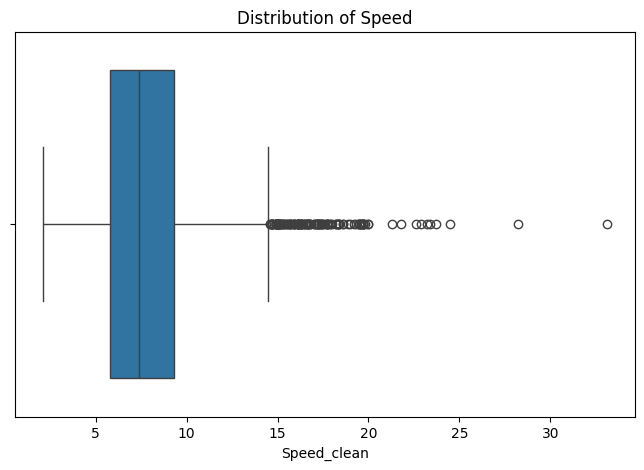

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df,x='Speed_clean')
plt.title('Distribution of Speed')
plt.show()

In [ ]:
Q1=df['Speed_clean'].quantile(0.25)
Q3=df['Speed_clean'].quantile(0.75)
IQR=Q3-Q1
lower=Q1-1.5*IQR
upper=Q3+1.5*IQR
print(lower,upper)

0.549999999999998 14.550000000000002


In [ ]:
df_clean=df[(df['Speed_clean']>= lower)&(df['Speed_clean']<=upper)]

In [ ]:
df.describe()

,Unnamed: 0,Speed_clean,Chip Time_clean
count,6397.000000,6227.000000,6227.000000
mean,537.356886,7.809571,5640.664645
std,381.548171,2.738633,4127.363020
min,0.000000,2.100000,772.781000
25%,213.000000,5.800000,2733.614000
50%,477.000000,7.400000,4358.800000
75%,797.000000,9.300000,7077.833000
max,1578.000000,33.100000,22445.366000


In [ ]:
df_clean.describe()

,Unnamed: 0,Speed_clean,Chip Time_clean
count,6087.000000,6087.000000,6087.000000
mean,542.242320,7.590734,5652.860672
std,376.258887,2.319583,4143.037687
min,0.000000,2.100000,989.291000
25%,219.000000,5.800000,2752.596000
50%,490.000000,7.400000,4356.048000
75%,797.000000,9.100000,7030.802000
max,1578.000000,14.500000,22445.366000


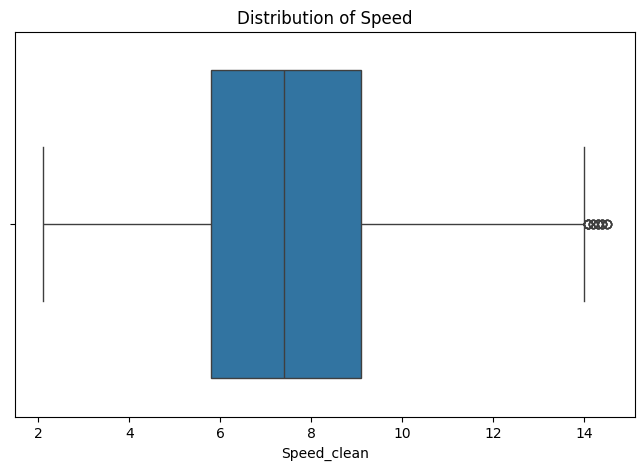

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df_clean,x='Speed_clean')
plt.title('Distribution of Speed')
plt.show()

#Task 6 — Written Justification

* Write 6–8 lines explaining:

* What issues were found

* What cleaning decisions were made

* Why those decisions are reasonable

In [ ]:
# some issues were found with this dataset such as:
# - incorrect data types: all numerical columns being objects
# - missing values: affects understanding the data
# - presence of outliers
# cleaning decisions so far:
# - changing datatypes of columns 'Speed' and 'Chip Time'
# - removing outliers found in 'Speed'
# those changes were made to better understand our current dataset, work more comfortably with it, and easily find insight in the future
